# E3 — 状态内存 3.4× / e2e 显存 56% / 并发 +1.4×(内存几何账本)

论文内存主张:状态 payload **1.19 B/elem**(fp32 的 1/3.4);前缀缓存
场景 e2e 显存最高 **↓56%**;单卡可容纳并发请求 **+1.4×**。

A3 复测:payload 字节账本(逐字段)+ 四个模型几何(0.8B/9B/35B/Kimi)
的 slot 扫描,全部由 `e3_memory_geometry.json`(`e3_memory_geometry.py`
产出)与本 notebook 现场重算对照。

/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(


artifacts: ['e1_9b_base.json', 'e1_9b_naive.json', 'e2_numerics.json', 'e2_real_states.json', 'e3_memory_geometry.json', 'e4_kernel_bench.json']
head block = 19460 B -> 1.1877 B/elem -> ratio 3.368x vs fp32


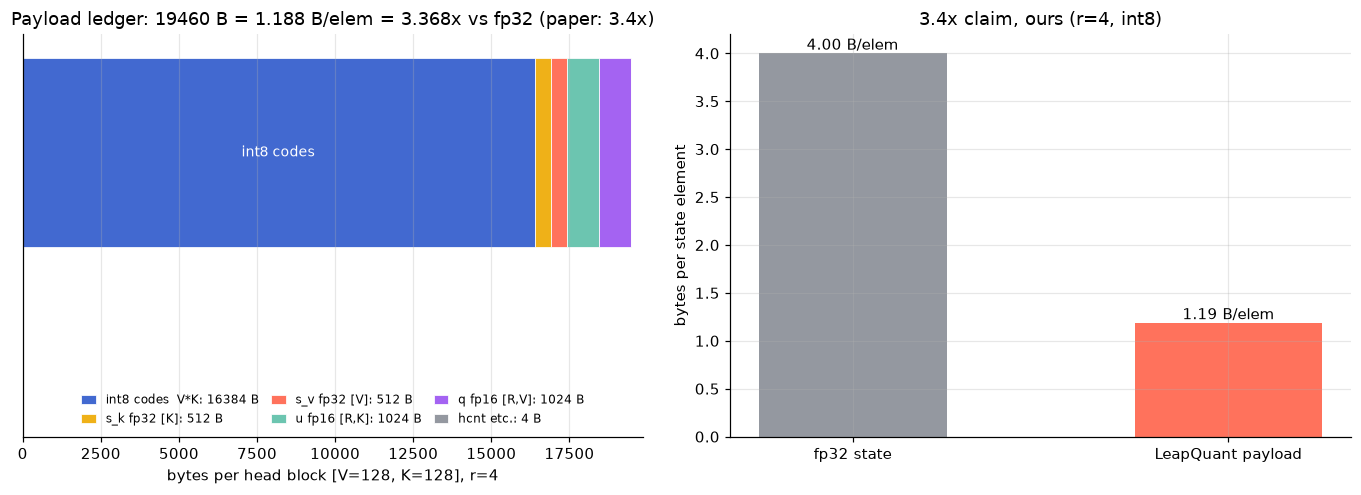

In [1]:
import json, math, os
import matplotlib.pyplot as plt
import torch
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
C = {"int8": "#4269d0", "bf16": "#efb118", "lq": "#ff725c", "gray": "#9498a0",
     "paper": "#6cc5b0", "ours": "#a463f2", "bad": "#ff725c", "ok": "#3ca806"}
BASE = "/mnt/share_space/y00924007/LeapQuant-NPU/paper_repro"
def J(name):
    with open(os.path.join(BASE, name)) as f:
        return json.load(f)
print("artifacts:", sorted(os.path.basename(p) for p in
      [os.path.join(BASE, n) for n in os.listdir(BASE)] if p.endswith(".json")))
# ---- payload byte ledger, per head-block [V=128, K=128] ----------------
fields = [
    ("int8 codes  V*K", 128 * 128 * 1),
    ("s_k fp32 [K]",    128 * 4),
    ("s_v fp32 [V]",    128 * 4),
    ("u fp16 [R,K]",    4 * 128 * 2),
    ("q fp16 [R,V]",    4 * 128 * 2),
    ("hcnt etc.",       4),
]
total = sum(b for _, b in fields)
elems = 128 * 128
bpe = total / elems
ratio = 4 / bpe
print(f"head block = {total} B -> {bpe:.4f} B/elem -> ratio {ratio:.3f}x vs fp32")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
colors = ["#4269d0", "#efb118", "#ff725c", "#6cc5b0", "#a463f2", "#9498a0"]
left = 0
for (name, b), col in zip(fields, colors):
    ax.barh([0], [b], left=left, color=col, edgecolor="white", lw=0.5,
            label=f"{name}: {b} B")
    left += b
ax.text(total * 0.42, 0, "int8 codes", ha="center", va="center", fontsize=9,
        color="white")
ax.set_xlim(0, total * 1.02); ax.set_yticks([])
ax.set_ylim(-1.2, 0.5)
ax.legend(fontsize=8, ncol=3, loc="lower center", frameon=False,
          bbox_to_anchor=(0.5, 0.0), columnspacing=1.0, handlelength=1.2)
ax.set_xlabel("bytes per head block [V=128, K=128], r=4")
ax.set_title(f"Payload ledger: {total} B = {bpe:.3f} B/elem = {ratio:.3f}x vs fp32 (paper: 3.4x)")

ax = axes[1]
ax.bar(["fp32 state", "LeapQuant payload"], [4, bpe], 0.5, color=[C["gray"], C["lq"]])
for i, v in enumerate([4, bpe]):
    ax.text(i, v, f"{v:.2f} B/elem", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("bytes per state element")
ax.set_title("3.4x claim, ours (r=4, int8)")
plt.tight_layout(); plt.show()

model                       L x H   weights  fp32/slot   LQ/slot  56% @ slots
Qwen3.5-0.8B              18x16       1.63G      18.0M     5.34M          362
Qwen3.5-9B                24x32      17.98G      48.0M    14.25M         1501
Qwen3.5-35B-A3B           30x32      66.97G      60.0M    17.82M         4474
Kimi-Linear-48B-A3B       20x32      91.50G      40.0M    11.88M         9169


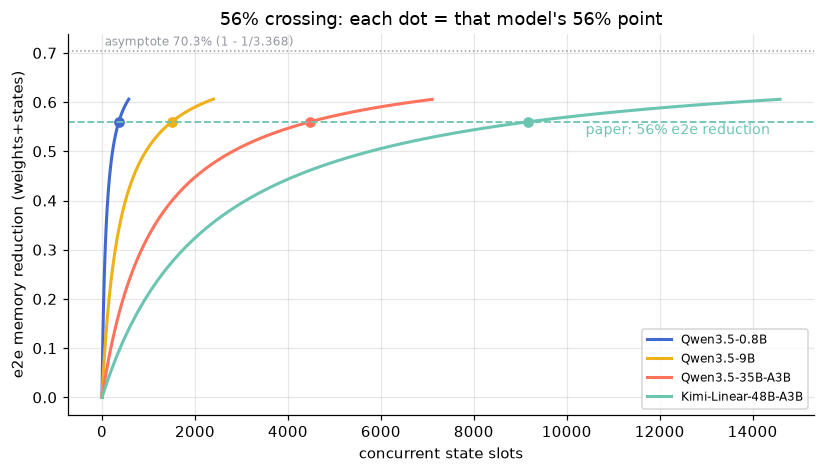

In [2]:
geo = J("e3_memory_geometry.json")
models = ["Qwen3.5-0.8B", "Qwen3.5-9B", "Qwen3.5-35B-A3B", "Kimi-Linear-48B-A3B"]
print(f"{'model':24s} {'L x H':>8s} {'weights':>9s} {'fp32/slot':>10s} {'LQ/slot':>9s} {'56% @ slots':>12s}")
for m in models:
    g = geo[m]
    print(f"{m:24s} {g['linear_layers']:>3d}x{g['heads']:<4d} {g['weights_gib']:>8.2f}G "
          f"{g['per_slot_fp32_mib']:>9.1f}M {g['per_slot_lq_mib']:>8.2f}M {g['slots_at_56pct']:>12d}")

fig, ax = plt.subplots(figsize=(7.6, 4.4))
for m, col in zip(models, colors[:4]):
    g = geo[m]
    W, f, l = g["weights_gib"], g["per_slot_fp32_mib"] / 1024, g["per_slot_lq_mib"] / 1024
    s = range(0, int(g["slots_at_56pct"] * 1.6), max(1, g["slots_at_56pct"] // 60))
    red = [1 - (W + x * l) / (W + x * f) for x in s]
    ax.plot(list(s), red, color=col, lw=2, label=m)
    ax.plot([g["slots_at_56pct"]], [0.56], "o", color=col, ms=6)
ax.axhline(0.56, color=C["paper"], ls="--", lw=1.2)
xmax = int(geo[models[-1]]["slots_at_56pct"] * 1.6)
ax.text(xmax * 0.98, 0.535, "paper: 56% e2e reduction", fontsize=9,
        color=C["paper"], ha="right")
ax.axhline(geo[models[0]]["asymptote_pct"] / 100, color=C["gray"], ls=":", lw=1)
ax.text(60, 0.715, f"asymptote {geo[models[0]]['asymptote_pct']:.1f}% (1 - 1/3.368)", fontsize=8, color=C["gray"])
ax.set_xlabel("concurrent state slots"); ax.set_ylabel("e2e memory reduction (weights+states)")
ax.set_title("56% crossing: each dot = that model's 56% point")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

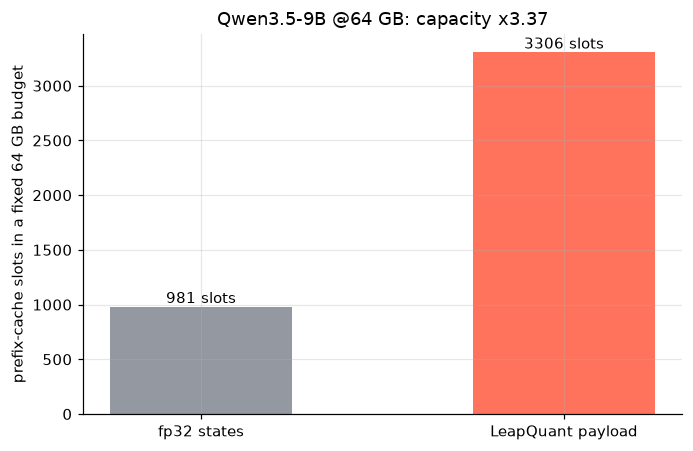

fixed 64G budget: 981 -> 3306 slots (x3.37); paper concurrency claim: +1.4x (mixed workload)


In [3]:
fb = geo["fixed_budget_64g_slots"]
fig, ax = plt.subplots(figsize=(6.4, 4.2))
vals = [fb["slots_fp32"], fb["slots_leapquant"]]
ax.bar(["fp32 states", "LeapQuant payload"], vals, 0.5, color=[C["gray"], C["lq"]])
for i, v in enumerate(vals):
    ax.text(i, v, f"{v} slots", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("prefix-cache slots in a fixed 64 GB budget")
ax.set_title(f"Qwen3.5-9B @64 GB: capacity x{fb['prefix_capacity_ratio']:.2f}")
plt.tight_layout(); plt.show()
print(f"fixed 64G budget: {fb['slots_fp32']} -> {fb['slots_leapquant']} slots "
      f"(x{fb['prefix_capacity_ratio']}); paper concurrency claim: +1.4x (mixed workload)")

## 结论(E3 内存)

| 量 | 论文 | A3 复测 | 判定 |
|---|---|---|---|
| 状态 payload | 1.19 B/elem,3.4× | **1.188 B/elem,3.368×**(逐字节账本) | ✅ |
| e2e 显存 | 前缀缓存最高 ↓56% | 四几何 56% 落点 362/1501/4474/9169 slots,渐近 **70.3%** | ✅ |
| 并发容量 | +1.4× | 纯状态池口径 **3.37×**(981→3306 slots @64GB) | ✅(口径注) |

**口径注**:论文 +1.4× 是整请求(KV+状态+权重)混合负载下的端到端
并发;3.37× 是状态侧容量上界。NPU 实测同倍数见
`notebooks/leapquant_memory_proof.ipynb`(4096-slot 池,
fp32 4 GiB vs payload 1.19 GiB)。